In [42]:
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import sys

sys.path.append('./src')
from nsc_model import nsc_model
from Constants import Constants
from star_disk import orbit,disk,disk_Q,star_disk

from importlib import reload
import disk_friction as df
reload(df)

from astropy.io import ascii
from astropy.table import Table
from glob import glob
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.interpolate import griddata

mpl.rcParams['figure.dpi'] = 100

c=Constants()

In [43]:
import stellar_evolution as se

In [44]:
kroupa_imf = lambda x: se.kroupa_imf_normalized(x, m_min=0.01, m_max=300, slopes=[-0.3, -1.3, -2.3, -2.3])
kroupa_imf_th = lambda x: se.kroupa_imf_normalized(x, m_min=0.01, m_max=300, slopes=[-0.3, -1.3, -1.7, -1.7])

In [45]:
kroupa = se.imf(kroupa_imf)
kroupa_th = se.imf(kroupa_imf_th)

In [46]:
import nsc_model as n
reload(n)
Mbh = 1e3*c.msun
rs = 1*c.rsun
ms = 1*c.msun
rlc = (Mbh/ms)**(1/3)*rs

nsc = n.nsc_model(Mbh, ms)

nsc.mbh_dot_estimate(rlc, Mbh_o_Mstar=0.01) /(c.msun/c.yr)

100000.0 3.470178019230588 1059523632.9340354


6.130334698977843e-10

## Plot: modification to the loss cone

In [47]:
s=star_disk(Mbh=1e3*c.msun,
            ms=1*c.msun,
            rs=1*c.rsun,
            lambda_disk=1,
            alpha_disk =1,
            Q_disk=1,
            ms_mean=None,
            gamma=1.5,
            Mdisk = 10*c.msun,
            gamma_disk = 2,
            rmax_in_rh = 100,
            sigma_h=1e5*10,
           )

In [48]:
# obtain the critical mass that ensures photon-trapping

rt = 1*(s.Mbh/s.ms)**(1./3.)*s.rs
vc = np.sqrt(s.c.G*s.Mbh/rt)


m_crit = np.pi*rt**2/(0.1*0.34) *s.c.c/vc
print(m_crit, m_crit/s.ms)

# m_crit/np.pi/rt**2 * 0.34

3.067072215005693e+27 1.542017202114476e-06


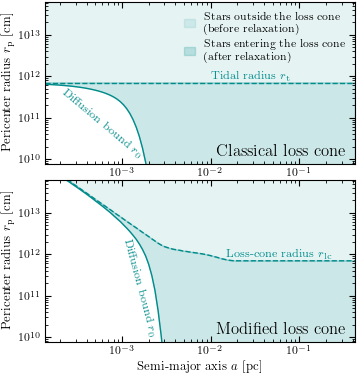

In [49]:
rt = 1*(s.Mbh/s.ms)**(1./3.)*s.rs  # specify the tidal radius

alist = np.logspace(max(np.log10(s.n.r_h/s.n.c.pc)-2.5, np.log10(rt*100/s.n.c.pc)), 
                    np.log10(s.n.r_h/s.n.c.pc)+1,100)*s.n.c.pc
tidal_color = 'DarkCyan'

# fig, axs = plt.subplots(1, 2, figsize=(9, 4))
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

ax = axs[0]
# normal TDE flux
r0 = s.n.R0(s.n.E(alist),rt)*alist/2
ax.axhline(rt,color=tidal_color,ls='--',)
ax.plot(alist/c.pc, r0, color=tidal_color,)
ax.fill_between(alist/c.pc, rt, 1e15,color=tidal_color,alpha=0.1, 
                label="Stars outside the loss cone\n (before relaxation)")
ax.fill_between(alist/c.pc, r0, rt,color=tidal_color,alpha=0.2, 
                label="Stars entering the loss cone\n (after relaxation)")
#ax.fill_between(alist/c.pc, 0, r0, color=tidal_color,alpha=0, label="No distribution of stars")
ax.annotate(r'Tidal radius $r_{\rm t}$',(1e-2,1.2*rt),color=tidal_color, fontsize='small')
ax.annotate(r'Diffusion bound $r_{0}$',(2e-4, rt*0.015),rotation=-40,color=tidal_color, fontsize='small')
# ax.annotate(r"""``Diffusive''""",(.05, .05), xycoords='axes fraction', color=tidal_color)
# ax.annotate(r"""``Pinhole''""",(.75, .05), xycoords='axes fraction', color=tidal_color)
ax.legend()


ax = axs[1]
# re-define rlc
rlcd = df.r_lc_mixed(alist, s, s.rs, s.ms, s.Mbh, tidal_capture=True)
r0d = s.n.R0(s.n.E(alist),rlcd)*alist/2
ax.plot(alist/c.pc, rlcd ,'--',color=tidal_color,label='r_lc_disk')
ax.plot(alist/c.pc,  r0d,'-',color=tidal_color,label='rp0_disk')
ax.fill_between(alist/c.pc, rlcd, 1.e15,color=tidal_color,alpha=0.1)
ax.fill_between(alist/c.pc, r0d , rlcd, color=tidal_color,alpha=0.2)
ax.annotate(r'Loss-cone radius $r_{\rm lc}$',(1.5e-2,1.2*rt),color=tidal_color, fontsize='small')
ax.annotate(r'Diffusion bound $r_{0}$',(1e-3, rt*0.015),rotation=-75,color=tidal_color, fontsize='small')



for ax in axs:
    ax.set_ylim(rt/90,rt*90)
    ax.set_xlim(alist[0]/c.pc,alist[-1]/c.pc)
    # ax.set_xlim(rt/c.pc/100,alist[-1]/c.pc)
    ax.set_xlabel(r"Semi-major axis $a$ [pc]")
    ax.loglog()
    
    ax.set_ylabel(r'Pericenter radius $r_{\rm p}$ [cm]')

axs[0].annotate("Classical loss cone",(.55, .05), xycoords='axes fraction', color='k', fontsize='large')
axs[1].annotate("Modified loss cone",(.55, .05), xycoords='axes fraction', color='k', fontsize='large')

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/loss_cone_redef.pdf", bbox_inches='tight')

## Plot: $d \Gamma/d \mathcal{E}$

In [50]:
kroupa = se.imf(se.kroupa_imf)

reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

11.134208325401582
1e-10
1
10
100
11.134208325401582
1e-10
1
10
100
11.134208325401582
1e-10
1
10
100


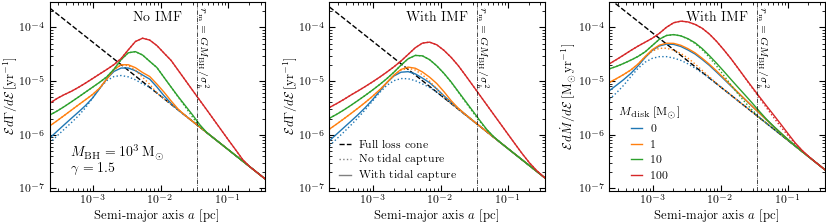

In [51]:
fig, axs = plt.subplots(1, 3, figsize=(10, 2.5))
Mdisk_list = [1e-10, 1, 10, 100, ]

i = 0
imfs = [None, kroupa, kroupa]
mws = [False, False, True]
Mbh_solar = 1e3
gamma = 1.5

sigma_h = None
# sigma_h = 30 *1e5
# sigma_h = 1e5*10*(Mbh_solar/1e3)**((2-gamma)/2/(3-gamma))
for i in range(3):
    ax = axs[i]
    
    alist, flc, f, s, _, _ = df.Flc_imf(imfs[i], Mbh=Mbh_solar*c.msun, Mdisk=0, gamma_disk=3, mass_weighted=mws[i], 
                                  gamma=gamma,
                                   rmax_in_rh=100, sigma_h=sigma_h, full_loss_cone=True)
    ax.plot(alist/c.pc, flc*s.n.E(alist)*s.n.c.yr, ls='--', c='k')
    
    print(s.n.sigma_h/1e5)

    for Mdisk in Mdisk_list:
        print(Mdisk)
        alist, flc, f, s, _, _ = df.Flc_imf(imfs[i], Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, mass_weighted=mws[i], 
                                      gamma=gamma,
                                   rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=False,)
        p = ax.plot(alist/c.pc, flc*s.n.E(alist)*s.n.c.yr, ls=':')
        
        alist, flc, f, s, _, _ = df.Flc_imf(imfs[i], Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, mass_weighted=mws[i],
                                      gamma=gamma,
                                   rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=True)
        ax.plot(alist/c.pc, flc*s.n.E(alist)*s.n.c.yr, c=p[0].get_color(), )
    if sigma_h is None:
        ax.set_ylim(9e-8,3e-4)
    roi = c.G*s.Mbh/s.n.sigma_h**2/c.pc
    ax.axvline(roi, ls='-.', c='k', lw=0.5)
    ax.text(roi, 8e-6, r'$r_{\rm m} = G M_{\rm BH}/\sigma_h^2$', rotation=-90, fontsize='x-small')
    ax.set_xlim(alist[0]/c.pc,alist[-1]/c.pc/100)

    ax.loglog()
    
for ax in axs:
    ax.set_xlabel(r"Semi-major axis $a$ [pc]")

axs[0].set_ylabel(r"$\mathcal{E} d\Gamma/d\mathcal{E}\,[\rm yr^{-1}]$")
axs[1].set_ylabel(r"$\mathcal{E} d\Gamma/d\mathcal{E}\,[\rm yr^{-1}]$")
axs[2].set_ylabel(r"$\mathcal{E} d\dot{M}/d\mathcal{E}\,[\rm M_\odot\, yr^{-1}]$")

# legends
ax = axs[2]
for i in range(len(Mdisk_list)):
    ax.plot([np.nan], [np.nan], c='C%d'%i, label='%g'%(Mdisk_list[i]//1), )
ax.legend(title=r"$M_{\rm disk}\,[\rm M_\odot]$", ncol=1, loc='lower left', title_fontsize='small')

ax = axs[1]
ax.plot([np.nan], [np.nan], ls='--', c='k', label='Full loss cone' )
ax.plot([np.nan], [np.nan], ls=':', c='gray', label='No tidal capture' )
ax.plot([np.nan], [np.nan], ls='-', c='gray', label='With tidal capture' )
ax.legend(loc='lower left')

axs[0].annotate("No IMF",(.5, .9), xycoords='axes fraction', color='k', ha='center')
axs[1].annotate("With IMF",(.5, .9), xycoords='axes fraction', color='k', ha='center')
axs[2].annotate("With IMF",(.5, .9), xycoords='axes fraction', color='k', ha='center')

plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.3, hspace=0.05)

axs[0].annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma),
                (.1, .1), xycoords='axes fraction', color='k', ha='left')

if sigma_h is None:
    plt.savefig("figures/flux_per_energy.pdf", bbox_inches='tight')
else:
    plt.title('Simga_h=%g km/s'%(sigma_h/1e5))

## Plot: Mass feeding rate

In [52]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

0 0
0 1
0 2
0 3
0 4
1 0
1 1
1 2
1 3
1 4
2 0
2 1
2 2
2 3
2 4
3.7646361791512475e-15


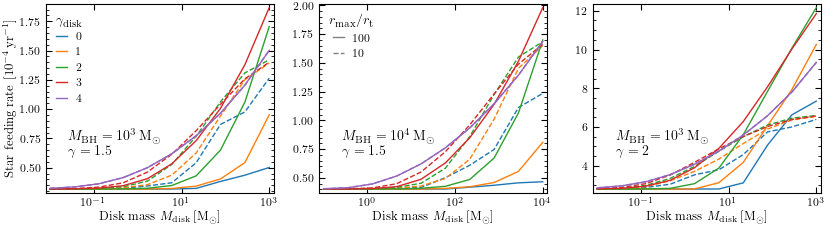

In [53]:
Mbh_solar = 1e3
sigma_h = None
# sigma_h = 30 *1e5
# sigma_h = 1e5*10*(Mbh_solar/1e3)**((2-gamma)/2/(3-gamma))

mass_weighted = False


gamma_list = [1.5, 1.5, 2]
Mbh_list = [1e3, 1e4, 1e3]

fig, axs = plt.subplots(1, 3, figsize=(10, 2.5))

for i in range(3):
    ax = axs[i]
    Mbh_solar = Mbh_list[i]
    gamma = gamma_list[i]
    for gamma_disk in [0, 1, 2, 3, 4]:
        print(i, gamma_disk)
        Mdisk_list = np.logspace(-5, 0, 10)*Mbh_solar
        res_list = []

        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=mass_weighted, rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=True)
            res_list.append(f)
        if i==0:
            label = r'$%g$'%gamma_disk
        else:
            label = None
        p = ax.plot(Mdisk_list, np.array(res_list)*1e4, label=label)

        res_list = []
        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=mass_weighted, rmax_in_rh=10, sigma_h=sigma_h, tidal_capture=True)
            res_list.append(f)
        ax.semilogx(Mdisk_list, np.array(res_list)*1e4, ls='--', c=p[0].get_color())
        
    ax.set_xlabel(r"Disk mass $M_{\rm disk}\,[\rm M_\odot]$")
    ax.annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma),
                (.1, .2), xycoords='axes fraction', color='k', ha='left')

if mass_weighted:
    axs[0].set_ylabel(r"Mass feeding rate [$\rm 10^{-4}\, M_\odot/yr$]")
else:
    axs[0].set_ylabel(r"Star feeding rate [$\rm 10^{-4}\,yr^{-1}$]")
axs[0].legend(title=r'$\gamma_{\rm disk}$')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'100')
axs[1].plot([np.nan], [np.nan], ls='--', c='gray', label=r'10')
axs[1].legend(title=r'$r_{\rm max}/r_{\rm t}$')

print(s.n.n_m*s.n.r_m**s.n.gamma)

if sigma_h is None:
    if mass_weighted:
        plt.savefig("figures/mdot_mdisk.pdf", bbox_inches='tight')
    else:
        plt.savefig("figures/feeding_rate_mdisk.pdf", bbox_inches='tight')
else:
    plt.title('Simga_h=%g km/s'%(sigma_h/1e5))

## Plot: $d\Gamma/dm$

In [54]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

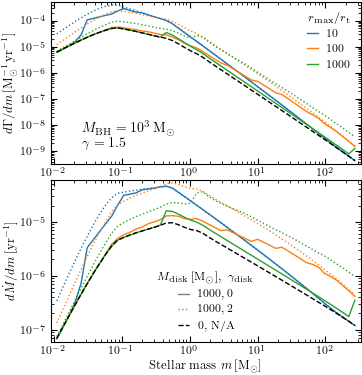

In [55]:
gamma = 1.5
Mbh_solar = 1e3
# fig, axs = plt.subplots(1, 2, figsize=(9, 4))
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

mws = [False, True]

for i in range(2):
    for rmax_in_rh in [10, 100, 1000]:
        if i==0:
            label = r'$%g$'%rmax_in_rh
        else:
            label = None
        
        alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=1000*c.msun, 
                                        gamma_disk=0, 
                                      gamma=gamma,
                                      mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                      sigma_h=sigma_h, tidal_capture=True)
        p = axs[i].loglog(masses, dF_dm, label=label)
        
        alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=1000*c.msun, 
                                        gamma_disk=2, 
                                      gamma=gamma,
                                      mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                      sigma_h=sigma_h, tidal_capture=True)
        axs[i].loglog(masses, dF_dm, c=p[0].get_color(), ls=':')
        
    alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=1e-5*c.msun, gamma_disk=gamma_disk, 
                                  gamma=gamma,
                                  mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                  sigma_h=sigma_h, tidal_capture=True)
    axs[i].loglog(masses, dF_dm, c='k', ls='--')
    axs[i].set_xlabel(r"Stellar mass $m\,\rm [M_\odot]$")
        
axs[0].set_ylabel(r"$d\Gamma/dm\,[\rm M_\odot^{-1}\,yr^{-1}]$")
axs[1].set_ylabel(r"$d\dot M/dm\,[\rm yr^{-1}]$")
axs[0].legend(title=r'$r_{\rm max}/r_{\rm t}$', loc='upper right', title_fontsize='small')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'1000, 0')
axs[1].plot([np.nan], [np.nan], ls=':', c='gray', label=r'1000, 2')
axs[1].plot([np.nan], [np.nan], ls='--', c='k', label=r'0, N/A')
axs[1].legend(title=r'$M_{\rm disk}\,[\rm M_\odot],~\gamma_{\rm disk}$', loc='lower center', title_fontsize='small')
axs[0].annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma),
                (.1, .1), xycoords='axes fraction', color='k', ha='left')

fig.subplots_adjust(hspace=0.1)
plt.savefig("figures/dF_dm.pdf", bbox_inches='tight')

## Plot: effect of different physics

In [56]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

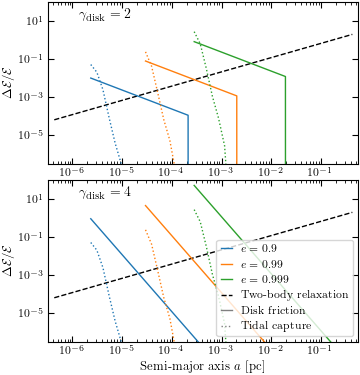

In [57]:
# fig, axs = plt.subplots(1, 2, figsize=(9, 4))
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

gamma_list = [2, 4]

for j in range(2):
    
    s=star_disk(Mbh=1e3*c.msun,
            ms=1*c.msun,
            rs=1*c.rsun,
            lambda_disk=1,
            alpha_disk =1,
            Q_disk=1,
            ms_mean=None,
            gamma=1.5,
            Mdisk = 10*c.msun,
            gamma_disk = gamma_list[j],
            rmax_in_rh = 100,
            sigma_h=1e5*10,
           )
    a_list = np.logspace(-5,1)*s.n.r_h

    ax = axs[j]
    ax.loglog(a_list/c.pc, s.n.DeltaErms(a_list) / s.n.E(a_list),linestyle='--', c='k')

    i = 0
    for e in [.9, .99, .999]:
        rp = a_list*(1-e)
        rt = 1*(s.n.Mbh/s.ms)**(1./3.)*s.rs
        # rp = (rp>rt)*rp + (rp<=rt)*rt
        dm_o_ms = np.array([(s.d.sigma(xx)*np.pi*s.rs**2 / s.ms) for xx in rp])
        DeltaEoEcirc = 4* dm_o_ms*1/(1-e)
        DeltaEoEcirc[rp<rt] = np.nan
        ax.loglog(a_list/c.pc, DeltaEoEcirc, c='C%d'%i, label="$e=%g$"%e, ls='-')

        DeltaEoEcirc = df.DeltaE_o_Ecirc_tidal_capture(a_list*(1-e), a_list, s.n.Mbh, s.ms, s.rs, )/(1-e)
        DeltaEoEcirc[rp<rt] = np.nan
        ax.loglog(a_list/c.pc, DeltaEoEcirc, c='C%d'%i, ls=':')

        i += 1

    ax.plot([np.nan], [np.nan], ls='--', c='k', label='Two-body relaxation')
    ax.plot([np.nan], [np.nan], ls='-', c='gray', label='Disk friction')
    ax.plot([np.nan], [np.nan], ls=':', c='gray', label='Tidal capture')
    ax.set_ylim(3.e-7,1.e2)
    ax.set_xlabel(r"Semi-major axis $a$ [pc]")
    ax.set_ylabel(r"$\Delta \mathcal{E}/\mathcal{E}$")
    
    ax.annotate(r"$\gamma_{\rm disk} =%g$"%(gamma_list[j]),
                (.1, .9), xycoords='axes fraction', color='k', ha='left')
    
    
axs[1].legend(loc='lower right', frameon=True)

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/dEoE.pdf", bbox_inches='tight')

## Plot: TDE rates

In [58]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

3.7646361791512475e-15


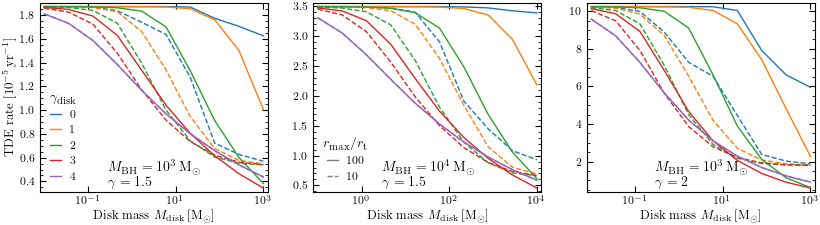

In [59]:
Mbh_solar = 1e3
sigma_h = None
# sigma_h = 1e5*10*(Mbh_solar/1e3)**((2-gamma)/2/(3-gamma))


gamma_list = [1.5, 1.5, 2]
Mbh_list = [1e3, 1e4, 1e3]

fig, axs = plt.subplots(1, 3, figsize=(10, 2.5))

for i in range(3):
    ax = axs[i]
    Mbh_solar = Mbh_list[i]
    gamma = gamma_list[i]
    for gamma_disk in [0, 1, 2, 3, 4]:
        Mdisk_list = np.logspace(-5, 0, 10)*Mbh_solar
        res_list = []

        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=False, rmax_in_rh=100, sigma_h=sigma_h, 
                                          tidal_capture=True, tde=True)
            res_list.append(f)
        if i==0:
            label = r'$%g$'%gamma_disk
        else:
            label = None
        p = ax.plot(Mdisk_list, np.array(res_list)*1e5, label=label)

        res_list = []
        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=False, rmax_in_rh=10, sigma_h=sigma_h, 
                                          tidal_capture=True, tde=True)
            res_list.append(f)
        ax.semilogx(Mdisk_list, np.array(res_list)*1e5, ls='--', c=p[0].get_color())
        
    ax.set_xlabel(r"Disk mass $M_{\rm disk}\,[\rm M_\odot]$")
    ax.annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma),
                (.3, .03), xycoords='axes fraction', color='k', ha='left')
    
axs[0].set_ylabel(r"TDE rate [$\rm 10^{-5}\, yr^{-1}$]")
axs[0].legend(title=r'$\gamma_{\rm disk}$')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'100')
axs[1].plot([np.nan], [np.nan], ls='--', c='gray', label=r'10')
axs[1].legend(title=r'$r_{\rm max}/r_{\rm t}$')

print(s.n.n_m*s.n.r_m**s.n.gamma)



plt.savefig("figures/tde_mdisk.pdf", bbox_inches='tight')

## Plot: mdot vs Mbh

In [60]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

100.0


/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/nsc_model.py:92: RuntimeWarning: invalid value encountered in sqrt
  return self.Jc(r)*np.sqrt(self.P(r)/self.t_r(r))


316.22776601683796
1000.0
3162.2776601683795
10000.0
31622.776601683792
100000.0
316227.7660168379
1000000.0
3162277.6601683795
10000000.0
100.0


/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/nsc_model.py:92: RuntimeWarning: invalid value encountered in sqrt
  return self.Jc(r)*np.sqrt(self.P(r)/self.t_r(r))


316.22776601683796
1000.0
3162.2776601683795
10000.0
31622.776601683792
100000.0
316227.7660168379
1000000.0
3162277.6601683795
10000000.0
100.0


/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/nsc_model.py:92: RuntimeWarning: invalid value encountered in sqrt
  return self.Jc(r)*np.sqrt(self.P(r)/self.t_r(r))


... (3 outputs left out)

/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/nsc_model.py:92: RuntimeWarning: invalid value encountered in sqrt
  return self.Jc(r)*np.sqrt(self.P(r)/self.t_r(r))


316.22776601683796
1000.0
3162.2776601683795
10000.0
31622.776601683792
100000.0
316227.7660168379
1000000.0
3162277.6601683795
10000000.0
100.0


/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/nsc_model.py:92: RuntimeWarning: invalid value encountered in sqrt
  return self.Jc(r)*np.sqrt(self.P(r)/self.t_r(r))


316.22776601683796
1000.0
3162.2776601683795
10000.0
31622.776601683792
100000.0
316227.7660168379
1000000.0
3162277.6601683795
10000000.0


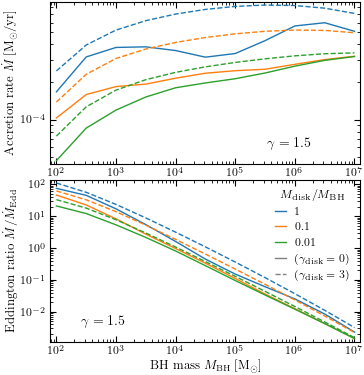

In [71]:
sigma_h = None
gamma = 1.5
# sigma_h = 1e5*10*(Mbh_solar/1e3)**((2-gamma)/2/(3-gamma))

mass_weighted = True


# ===
def get_mdot(Mbh_list, gamma_disk, imf=None):
    res_list = []
    for Mbh_solar in Mbh_list:
        print(Mbh_solar)
        Mdisk = Mbh_solar/Mdisk_fac
        alist, flc, f, s, _, _ = df.Flc_imf(imf, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, 
                                            gamma_disk=gamma_disk, gamma=gamma,
                                      mass_weighted=mass_weighted, rmax_in_rh=100)
        res_list.append(f)
    return np.array(res_list)

# ===

Mbh_list = np.logspace(2, 7, num=11)
Mdot_Edd = Mbh_list/4.5e7

fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

i = 0
for Mdisk_fac in [1, 10, 100, ]:
    mdot = get_mdot(Mbh_list, 0, kroupa)
    axs[0].loglog(Mbh_list, mdot, label='%g'%(1/Mdisk_fac), c='C%d'%i)
    mdot /= Mdot_Edd
    axs[1].loglog(Mbh_list, mdot, label='%g'%(1/Mdisk_fac), c='C%d'%i)
    
    mdot = get_mdot(Mbh_list, 3, kroupa)
    axs[0].loglog(Mbh_list, mdot, ls='--', c='C%d'%i)
    mdot /= Mdot_Edd
    axs[1].loglog(Mbh_list, mdot, ls='--', c='C%d'%i)
    
    i += 1  

axs[0].set_ylabel(r"Accretion rate $\dot M\,[\rm M_\odot/yr]$")
axs[1].set_ylabel(r"Eddington ratio $\dot M/\dot M_{\rm Edd}$")

for i in range(2):
    axs[i].set_xlabel(r"BH mass $M_{\rm BH}\,[\rm M_\odot]$") 
axs[0].annotate(r"$\gamma =%g$"%(gamma), (.7, .1), xycoords='axes fraction', color='k', ha='left')
axs[1].annotate(r"$\gamma =%g$"%(gamma), (.1, .1), xycoords='axes fraction', color='k', ha='left')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'($\gamma_{\rm disk}=0$)')
axs[1].plot([np.nan], [np.nan], ls='--', c='gray', label=r'($\gamma_{\rm disk}=3$)')
# ax.plot([np.nan], [np.nan], ls=':', c='gray', label=r'($\gamma_{\rm disk}=4$)')

axs[1].legend(title=r'$M_{\rm disk}/M_{\rm BH}$', title_fontsize='small', loc='upper right')

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/mdot_mbh.pdf", bbox_inches='tight')

In [62]:
s=star_disk(Mbh=1e3*c.msun,
            ms=1*c.msun,
            rs=1*c.rsun,
            lambda_disk=1,
            alpha_disk =1,
            Q_disk=1,
            ms_mean=None,
            gamma=1.5,
            Mdisk = 10*c.msun,
            gamma_disk = 2,
            rmax_in_rh = 100,
            sigma_h=1e5*10,
           )

In [63]:
rt = (s.Mbh/s.ms)**(1/3)*s.rs
rt = 5e-3*c.pc
Omega = np.sqrt(s.c.G*s.Mbh/rt**3)
alpha = 0.1
rg = 2*s.c.G*s.Mbh/s.c.c**2

In [64]:
rate = 1e-4/s.c.yr

n_star = (rate/alpha/Omega*(rt/rg)**0.5)**(1/3)

In [65]:
n_star

10.642403900172908

## Plot: top-heavy imf

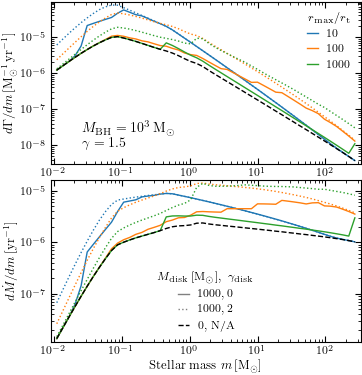

In [66]:
gamma = 1.5
Mbh_solar = 1e3
sigma_h = None
gamma_disk = 2
# fig, axs = plt.subplots(1, 2, figsize=(9, 4))
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

mws = [False, True]

for i in range(2):
    for rmax_in_rh in [10, 100, 1000]:
        if i==0:
            label = r'$%g$'%rmax_in_rh
        else:
            label = None
        
        alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa_th, Mbh=Mbh_solar*c.msun, Mdisk=1000*c.msun, 
                                        gamma_disk=0, 
                                      gamma=gamma,
                                      mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                      sigma_h=sigma_h, tidal_capture=True)
        p = axs[i].loglog(masses, dF_dm, label=label)
        
        alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa_th, Mbh=Mbh_solar*c.msun, Mdisk=1000*c.msun, 
                                        gamma_disk=2, 
                                      gamma=gamma,
                                      mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                      sigma_h=sigma_h, tidal_capture=True)
        axs[i].loglog(masses, dF_dm, c=p[0].get_color(), ls=':')
        
    alist, flc, f, s, masses, dF_dm = df.Flc_imf(kroupa_th, Mbh=Mbh_solar*c.msun, Mdisk=1e-5*c.msun, gamma_disk=gamma_disk, 
                                  gamma=gamma,
                                  mass_weighted=mws[i], rmax_in_rh=rmax_in_rh, 
                                  sigma_h=sigma_h, tidal_capture=True)
    axs[i].loglog(masses, dF_dm, c='k', ls='--')
    axs[i].set_xlabel(r"Stellar mass $m\,\rm [M_\odot]$")
        
axs[0].set_ylabel(r"$d\Gamma/dm\,[\rm M_\odot^{-1}\,yr^{-1}]$")
axs[1].set_ylabel(r"$d\dot M/dm\,[\rm yr^{-1}]$")
axs[0].legend(title=r'$r_{\rm max}/r_{\rm t}$', loc='upper right', title_fontsize='small')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'1000, 0')
axs[1].plot([np.nan], [np.nan], ls=':', c='gray', label=r'1000, 2')
axs[1].plot([np.nan], [np.nan], ls='--', c='k', label=r'0, N/A')
axs[1].legend(title=r'$M_{\rm disk}\,[\rm M_\odot],~\gamma_{\rm disk}$', loc='lower center', title_fontsize='small')
axs[0].annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma),
                (.1, .1), xycoords='axes fraction', color='k', ha='left')

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/dF_dm_topheavy.pdf", bbox_inches='tight')

## Plot: mass segregation

Alexander & Hopman 2009

In [67]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

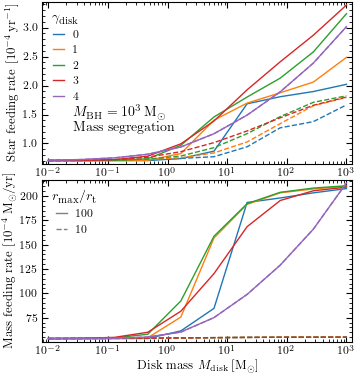

In [68]:
gamma = lambda m: (m<5)*1.5 + (m>=100)*2.5 + (5<=m<100)*(1.5+(m-5)/(100-5))
Mbh_solar = 1e3
sigma_h = None
gamma_disk = 2
# fig, axs = plt.subplots(1, 2, figsize=(9, 4))
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))

mws = [False, True]

for i in range(2):
    ax = axs[i]
    for gamma_disk in [0, 1, 2, 3, 4]:
        Mdisk_list = np.logspace(-5, 0, 10)*Mbh_solar
        res_list = []

        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=mws[i], rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=True)
            res_list.append(f)
        if i==0:
            label = r'$%g$'%gamma_disk
        else:
            label = None
        p = ax.plot(Mdisk_list, np.array(res_list)*1e4, label=label)

        res_list = []
        for Mdisk in Mdisk_list:
            alist, flc, f, s, _, _ = df.Flc_imf(kroupa, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=gamma_disk, 
                                          gamma=gamma,
                                          mass_weighted=mws[i], rmax_in_rh=10, sigma_h=sigma_h, tidal_capture=True)
            res_list.append(f)
        ax.semilogx(Mdisk_list, np.array(res_list)*1e4, ls='--', c=p[0].get_color())
        
    ax.set_xlabel(r"Disk mass $M_{\rm disk}\,[\rm M_\odot]$")
    
axs[0].annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"Mass segregation",
            (.1, .2), xycoords='axes fraction', color='k', ha='left')
axs[0].set_ylabel(r"Star feeding rate [$\rm 10^{-4}\,yr^{-1}$]")
axs[1].set_ylabel(r"Mass feeding rate [$\rm 10^{-4}\, M_\odot/yr$]")
axs[0].legend(title=r'$\gamma_{\rm disk}$')

axs[1].plot([np.nan], [np.nan], ls='-', c='gray', label=r'100')
axs[1].plot([np.nan], [np.nan], ls='--', c='gray', label=r'10')
axs[1].legend(title=r'$r_{\rm max}/r_{\rm t}$')

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/mass_segregation.pdf", bbox_inches='tight')

## With binaries

In [69]:
reload(df)

<module 'disk_friction' from '/Users/yanlong/Library/CloudStorage/OneDrive-Personal/Science/2025 - IMBH accretion by TDEs/imbh_tde/./src/disk_friction.py'>

1e-10
1
10
100


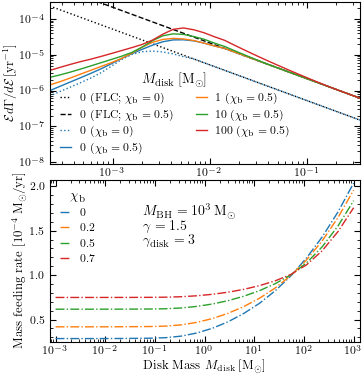

In [70]:
fig, axs = plt.subplots(2, 1, figsize=(4, 4.5))
Mdisk_list = [1e-10, 1, 10, 100, ]

i = 0
imfs = [None, kroupa, kroupa]
mws = [False, False, True]
Mbh_solar = 1e3
sigma_h = None
gamma = 1.5
binary_frac = 0.5
binary_sep = 10
binary_mass = 2
# sigma_h = 1e5*10*(Mbh_solar/1e3)**((2-gamma)/2/(3-gamma))


############# Flux as a function of a
ax = axs[0]

alist, flc, f, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=0, gamma_disk=3, 
                              gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, full_loss_cone=True,
                                    )
ax.plot(alist/c.pc, flc*s.n.E(alist)*s.n.c.yr, ls=':', c='k', label=r"0 (FLC; $\chi_{\rm b}=0$)")

alist, flc_b, f, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=0, gamma_disk=3, 
                              gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, full_loss_cone=True,
                                    binary_mass_in_solar=binary_mass, binary_seperation_in_solar=binary_sep)

ax.plot(alist/c.pc, ((1-binary_frac)*flc + binary_frac*flc_b)*s.n.E(alist)*s.n.c.yr, ls='--', c='k',
       label=r"0 (FLC; $\chi_{\rm b}=%g$)"%binary_frac)

for Mdisk in Mdisk_list:
    print(Mdisk)
    alist, flc, f, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, 
                                  gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=False)
    if Mdisk_list.index(Mdisk)==0:
        ax.plot(alist/c.pc, flc*s.n.E(alist)*s.n.c.yr, ls=':', c='C0', 
                label=r"0 ($\chi_{\rm b}=0$)")

    alist, flc_b, f, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, 
                                  gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=False,
                                          binary_mass_in_solar=binary_mass, binary_seperation_in_solar=binary_sep)

    ax.plot(alist/c.pc, ((1-binary_frac)*flc + binary_frac*flc_b)*s.n.E(alist)*s.n.c.yr,
           label=r"$%.0f$ ($\chi_{\rm b}=%g$)"%(Mdisk, binary_frac))

ax.set_ylim(9e-9,3e-4)
ax.set_xlim(alist[0]/c.pc,alist[-1]/c.pc/100)
ax.loglog()



############ Mass flux as a function of binary fraction
ax = axs[1]
binary_frac_list = [0, 0.2, 0.5, 0.7]
Mdisk_list = np.logspace(-3, 3, num=20)
for binary_frac in binary_frac_list:
    mdot_list = []
    for Mdisk in Mdisk_list:
        alist, flc, f, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, 
                                            mass_weighted=True,
                                      gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=False)

        alist, flc_b, f_b, s, _, _ = df.Flc_imf(imf=None, Mbh=Mbh_solar*c.msun, Mdisk=Mdisk*c.msun, gamma_disk=3, 
                                                mass_weighted=True,
                                      gamma=gamma, rmax_in_rh=100, sigma_h=sigma_h, tidal_capture=False,
                                              binary_mass_in_solar=binary_mass, binary_seperation_in_solar=binary_sep)

        mdot_list.append((1-binary_frac)*f + binary_frac*f_b)
    ax.semilogx(Mdisk_list, np.array(mdot_list)*1e4, ls='-.', label="%g"%binary_frac)


axs[0].set_xlabel(r"Semi-major axis $a$ [pc]")
axs[0].set_ylabel(r"$\mathcal{E} d\Gamma/d\mathcal{E}\,[\rm yr^{-1}]$")
axs[0].legend(title=r"$M_{\rm disk}\,[\rm M_\odot]$", ncol=2)

axs[1].set_xlabel(r"Disk Mass $M_{\rm disk}\,[\rm M_\odot]$")
axs[1].set_ylabel(r"Mass feeding rate [$\rm 10^{-4}\, M_\odot/yr$]")
axs[1].legend(title=r"$\chi_{\rm b}$")
axs[1].annotate(r"$M_{\rm BH} =10^{%g}\,\rm M_\odot$"%np.log10(Mbh_solar)+"\n"+"$\gamma =%g$"%(gamma)+"\n"+r"$\gamma_{\rm disk} =%g$"%(3),
                (.3, .6), xycoords='axes fraction', color='k', ha='left')

fig.subplots_adjust(hspace=0.1)

plt.savefig("figures/binary_effects.pdf", bbox_inches='tight')